# Лабораторная работа № 5
## Ансамбли моделей машинного обучения. Часть 1

Дисциплина «Технологии машинного обучения»

**Цель.** Изучить ансамблевые методы и сравнить их на задаче бинарной классификации.

**Задание.** Подготовить данные, разделить их методом `train_test_split`, обучить две модели группы бэггинга, AdaBoost и градиентный бустинг. Сравнить качество четырёх моделей на тестовой выборке.

Материалы курса

- [Задание лабораторной работы](https://github.com/ugapanyuk/courses_current/wiki/LAB_TMO_ENSEMBLES_1)
- [Бэггинг и случайный лес](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/ensembles/bagging_forest.ipynb)
- [Бустинг](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/ensembles/boosting.ipynb)
- [Оценка качества моделей](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/metrics/metrics.ipynb)

## 1. Загрузка библиотек и данных

Используем Online Shoppers Purchasing Intention Dataset. Каждая строка описывает один сеанс посещения интернет-магазина. Целевой признак `Revenue` принимает значение `True`, если сеанс завершился покупкой. По характеристикам сеанса решаем задачу бинарной классификации.

Данные опубликованы C. Sakar и Y. Kastro в 2018 году. Лицензия CC BY 4.0. [Описание набора данных UCI](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) · [Исходный CSV](https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv)

Для повторного запуска нужны ядро Python и библиотеки `pandas`, `matplotlib` и `scikit-learn`. Результаты получены с `scikit-learn 1.7.2`. Файл `online_shoppers_intention.csv` лежит рядом с ноутбуком.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
DATA_PATH = Path('online_shoppers_intention.csv')
if not DATA_PATH.is_file():
    DATA_PATH = Path('lab5') / DATA_PATH
if not DATA_PATH.is_file():
    DATA_PATH = Path('labs_ml') / DATA_PATH

data = pd.read_csv(DATA_PATH)
print(f'Строк — {data.shape[0]:,}, столбцов — {data.shape[1]}.'.replace(',', ' '))
display(data.head())

Строк — 12 330  столбцов — 18.


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Анализ и подготовка данных

Проверим пропуски, типы признаков, число совпадающих строк и распределение классов.

In [2]:
feature_summary = pd.DataFrame({
    'Тип данных': data.dtypes.astype(str),
    'Пропуски': data.isna().sum(),
    'Уникальные значения': data.nunique(),
})
display(feature_summary)

print(f'Совпадающих строк сверх первого экземпляра — {data.duplicated().sum()}.')
class_counts = data['Revenue'].value_counts().rename(index={False: 'Без покупки', True: 'Покупка'})
display(pd.DataFrame({
    'Число сеансов': class_counts,
    'Доля, %': (100 * class_counts / len(data)).round(2),
}))

,Тип данных,Пропуски,Уникальные значения
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


Совпадающих строк сверх первого экземпляра — 125.


,Число сеансов,"Доля, %"
Revenue,,
Без покупки,10422,84.53
Покупка,1908,15.47


Проверка показала, что пропусков нет. По описанию UCI каждому сеансу соответствует отдельный посетитель, поэтому сохраняем строки с одинаковыми значениями признаков.

Исключим `PageValues`. Этот показатель связан с ценностью страниц по данным о транзакциях, а задача сравнения ограничена характеристиками посещения, включая его продолжительность и посещённые страницы.

Применим one-hot кодирование к месяцу, типу посетителя, признаку выходного и числовым кодам операционной системы, браузера, региона и источника трафика. Коды обозначают категории. Остальные признаки передадим моделям в исходном масштабе, который подходит деревьям решений.

In [3]:
X = data.drop(columns=['Revenue', 'PageValues'])
y = data['Revenue'].astype(int)

categorical_columns = [
    'Month', 'OperatingSystems', 'Browser', 'Region',
    'TrafficType', 'VisitorType', 'Weekend',
]

preprocessor = ColumnTransformer(
    [('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_columns)],
    remainder='passthrough',
)

## 3. Разбиение на обучающую и тестовую выборки

Выделим 20% данных на тест. Стратификация по `Revenue` сохранит близкую долю покупок в обеих выборках. Кодировщик обучается внутри каждого конвейера на обучающих данных.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)

sample_summary = pd.DataFrame({
    'Число сеансов': [len(y_train), len(y_test)],
    'Покупки': [y_train.sum(), y_test.sum()],
    'Доля покупок, %': [100 * y_train.mean(), 100 * y_test.mean()],
}, index=['Обучающая', 'Тестовая'])
display(sample_summary.round(2))

,Число сеансов,Покупки,"Доля покупок, %"
Обучающая,9864,1526,15.47
Тестовая,2466,382,15.49


## 4. Обучение ансамблей

- **Бэггинг.** Обучаем деревья на бутстрэп-выборках и усредняем их оценки вероятности покупки. Каждое дерево рассматривает все признаки при поиске разбиения.
- **Случайный лес.** Деревья также обучаются на бутстрэп-выборках. В каждом узле выбирается случайное подмножество признаков для поиска разбиения (`max_features='sqrt'`).
- **AdaBoost.** Последовательно обучаем деревья глубины 1. В алгоритме SAMME после каждого шага увеличиваются веса объектов, которые добавленное дерево классифицировало ошибочно.
- **Градиентный бустинг.** Последовательно добавляем деревья глубины до 3. Каждое дерево аппроксимирует отрицательный градиент логарифмической функции потерь по текущим прогнозам.

Для бэггинга и случайного леса зададим одинаковые ограничения на глубину и минимальный размер листа. Все настройки фиксируем до оценки на тесте.

In [5]:
estimators = {
    'Бэггинг': BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=8, min_samples_leaf=10),
        n_estimators=100,
        random_state=SEED,
    ),
    'Случайный лес': RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_leaf=10,
        max_features='sqrt',
        random_state=SEED,
    ),
    'AdaBoost': AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        learning_rate=0.5,
        random_state=SEED,
    ),
    'Градиентный бустинг': GradientBoostingClassifier(
        n_estimators=100,
        max_depth=3,
        min_samples_leaf=10,
        learning_rate=0.1,
        random_state=SEED,
    ),
}

models = {}
for name, estimator in estimators.items():
    model = Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('classifier', estimator),
    ])
    models[name] = model.fit(X_train, y_train)
    print(f'{name} — обучение завершено.')

Бэггинг — обучение завершено.


Случайный лес — обучение завершено.


AdaBoost — обучение завершено.


Градиентный бустинг — обучение завершено.


## 5. Сравнение моделей на тестовой выборке

Для сравнения используем **Average Precision (AP)** по классу «покупка». Метрика усредняет точность (precision) по порогам с весами, равными приросту полноты (recall). Чем выше AP, тем лучше модель ранжирует сеансы с покупкой. Оценка использует вероятности класса и подходит для сравнения при малой доле покупок.

На графике горизонтальная линия показывает долю покупок в тестовой выборке. Она служит ориентиром для ранжирования, независимого от целевого класса.

,Модель,Average Precision
0,Бэггинг,0.3520
1,Случайный лес,0.3487
2,Градиентный бустинг,0.3460
3,AdaBoost,0.3068


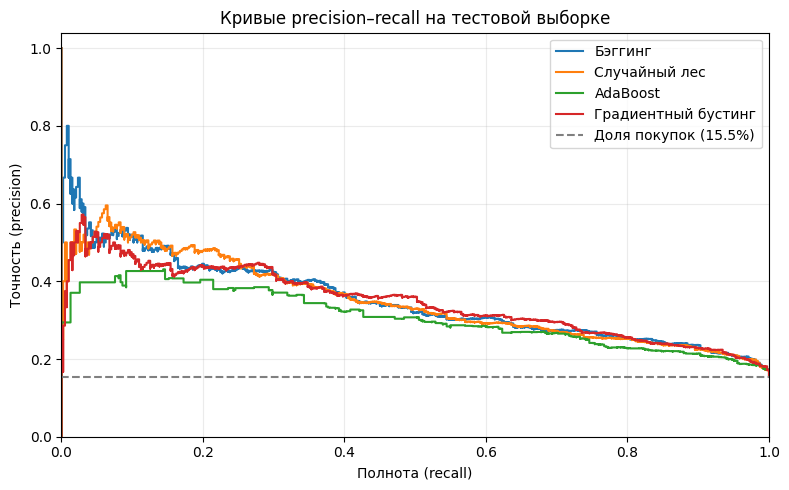

In [6]:
scores = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}
results = pd.DataFrame({
    'Модель': list(scores),
    'Average Precision': [average_precision_score(y_test, score) for score in scores.values()],
}).sort_values('Average Precision', ascending=False, ignore_index=True)

display(results.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for name, score in scores.items():
    precision, recall, _ = precision_recall_curve(y_test, score)
    ax.step(recall, precision, where='post', label=name)

test_prevalence = y_test.mean()
ax.axhline(
    test_prevalence, color='gray', linestyle='--',
    label=f'Доля покупок ({test_prevalence:.1%})',
)
ax.set(
    title='Кривые precision–recall на тестовой выборке',
    xlabel='Полнота (recall)',
    ylabel='Точность (precision)',
    xlim=(0, 1),
    ylim=(0, 1.04),
)
ax.grid(alpha=0.25)
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()

## Вывод

1. Для обучения использовали 9 864 сеанса, для тестирования — 2 466. В тестовой выборке 382 сеанса завершились покупкой (15,49%). Категориальные признаки закодированы на обучающей выборке. Показатель `PageValues` исключён из признаков из-за его связи с данными о транзакциях.
2. На тестовой выборке наибольшую AP показал бэггинг (0,3520). Случайный лес получил 0,3487, градиентный бустинг — 0,3460. Разница между лучшим и третьим результатом составила около 0,006. У AdaBoost AP составила 0,3068.
3. Все четыре модели превысили ориентир 0,1549, равный доле покупок в тестовой выборке. Ранжирование моделей относится к выбранному разбиению выборки и заданным гиперпараметрам.